In [9]:
%pip install pandas numpy matplotlib seaborn scikit-learn joblib xgboost

Note: you may need to restart the kernel to use updated packages.


In [10]:
import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

warnings.filterwarnings("ignore")

PROJECT_DIR = r"C:\Users\adity\Downloads\Historical data\BharatMarket_AI"

FEATURE_DIR = os.path.join(PROJECT_DIR, "data", "features")
MODEL_DIR = os.path.join(PROJECT_DIR, "outputs", "models")
REPORT_DIR = os.path.join(PROJECT_DIR, "outputs", "reports")
CHART_DIR = os.path.join(PROJECT_DIR, "outputs", "charts")
FORECAST_DIR = os.path.join(PROJECT_DIR, "data", "forecasts")

for folder in [
    MODEL_DIR,
    REPORT_DIR,
    CHART_DIR,
    FORECAST_DIR
]:
    os.makedirs(folder, exist_ok=True)

INSTRUMENTS = [
    "NIFTY50",
    "BANKNIFTY",
    "RELIANCE",
    "TCS",
    "HDFCBANK",
    "INFY",
    "ICICIBANK",
    "SBIN",
    "ITC",
    "LT"
]

TEST_SIZE = 0.20
RANDOM_STATE = 42

# Correct target names generated by Notebook 03
TARGET_COLUMN = "target_next_close"
CURRENT_PRICE_COLUMN = "close"

print("BharatMarket AI")
print("Notebook 07: Machine Learning Forecasting")
print("-" * 55)
print("Project directory:", PROJECT_DIR)
print("Target:", TARGET_COLUMN)
print("Configuration completed.")

BharatMarket AI
Notebook 07: Machine Learning Forecasting
-------------------------------------------------------
Project directory: C:\Users\adity\Downloads\Historical data\BharatMarket_AI
Target: target_next_close
Configuration completed.


In [11]:
def load_model_data(symbol):

    file_path = os.path.join(
        FEATURE_DIR,
        f"{symbol}_model_ready.csv"
    )

    if not os.path.exists(file_path):
        raise FileNotFoundError(
            f"Dataset not found: {file_path}"
        )

    df = pd.read_csv(file_path)

    if "date" not in df.columns:
        raise ValueError(
            f"{symbol}: date column is missing."
        )

    df["date"] = pd.to_datetime(
        df["date"],
        errors="coerce"
    )

    df = df.dropna(subset=["date"])
    df = df.sort_values("date")
    df = df.drop_duplicates(
        subset=["date"],
        keep="last"
    )

    return df.reset_index(drop=True)


market_data = {}

for symbol in INSTRUMENTS:

    try:
        df = load_model_data(symbol)
        market_data[symbol] = df

        print(
            f"{symbol}: {len(df)} records loaded"
        )

    except Exception as error:
        print(f"{symbol}: ERROR — {error}")

print("\nTotal instruments loaded:", len(market_data))

NIFTY50: 1034 records loaded
BANKNIFTY: 1033 records loaded
RELIANCE: 1037 records loaded
TCS: 1037 records loaded
HDFCBANK: 1037 records loaded
INFY: 1037 records loaded
ICICIBANK: 1037 records loaded
SBIN: 1037 records loaded
ITC: 1037 records loaded
LT: 1037 records loaded

Total instruments loaded: 10


In [12]:
if "NIFTY50" not in market_data:
    raise ValueError(
        "NIFTY50 dataset could not be loaded. "
        "Check Notebook 03 output files."
    )

nifty_df = market_data["NIFTY50"]

print("NIFTY50 dataset shape:", nifty_df.shape)

print("\nDataset columns:")
print(nifty_df.columns.tolist())

print("\nTarget verification:")

EXPECTED_TARGETS = [
    "target_next_close",
    "target_next_return",
    "target_next_direction"
]

for column in EXPECTED_TARGETS:

    status = (
        "FOUND"
        if column in nifty_df.columns
        else "MISSING"
    )

    print(f"{column}: {status}")

if TARGET_COLUMN not in nifty_df.columns:

    raise ValueError(
        f"'{TARGET_COLUMN}' is missing from the NIFTY50 "
        "model-ready dataset. Rerun Notebook 03 and verify "
        "that target columns were generated and exported."
    )

if CURRENT_PRICE_COLUMN not in nifty_df.columns:

    raise ValueError(
        f"'{CURRENT_PRICE_COLUMN}' is missing. "
        "The current closing price is required for "
        "directional accuracy."
    )

print("\nTarget verification successful.")

display(nifty_df.head())

NIFTY50 dataset shape: (1034, 66)

Dataset columns:
['date', 'adj_close', 'close', 'high', 'low', 'open', 'volume', 'daily_return', 'weekly_return', 'monthly_return', 'sma_5', 'sma_10', 'sma_20', 'sma_50', 'sma_100', 'sma_200', 'ema_9', 'ema_12', 'ema_20', 'ema_26', 'ema_50', 'rsi_14', 'macd', 'macd_signal', 'macd_histogram', 'bb_middle', 'bb_upper', 'bb_lower', 'bb_width', 'bb_position', 'true_range', 'atr_14', 'atr_percentage', 'volatility_10', 'volatility_20', 'volatility_50', 'volume_change', 'volume_sma_10', 'volume_sma_20', 'volume_ratio', 'candle_body', 'candle_body_percentage', 'high_low_range', 'high_low_range_percentage', 'upper_wick', 'lower_wick', 'price_gap_percentage', 'close_lag_1', 'return_lag_1', 'close_lag_2', 'return_lag_2', 'close_lag_3', 'return_lag_3', 'close_lag_5', 'return_lag_5', 'close_lag_10', 'return_lag_10', 'year', 'month', 'day', 'day_of_week', 'quarter', 'week_of_year', 'target_next_close', 'target_next_return', 'target_next_direction']

Target verificat

,date,adj_close,close,high,low,open,volume,daily_return,weekly_return,monthly_return,...,return_lag_10,year,month,day,day_of_week,quarter,week_of_year,target_next_close,target_next_return,target_next_direction
0,2022-09-09,17833.349609,17833.349609,17925.949219,17786.000000,17923.349609,270300,0.194393,1.675653,1.758906,...,-0.468618,2022,9,9,4,3,36,17936.349609,0.577570,1.0
1,2022-09-12,17936.349609,17936.349609,17980.550781,17889.150391,17890.849609,228200,0.577570,1.531484,2.290307,...,0.208026,2022,9,12,0,3,37,18070.050781,0.745420,1.0
2,2022-09-13,18070.050781,18070.050781,18088.300781,18015.449219,18044.449219,259900,0.745420,2.347421,2.327713,...,-1.400999,2022,9,13,1,3,37,18003.750000,-0.366910,0.0
3,2022-09-14,18003.750000,18003.750000,18091.550781,17771.150391,17771.150391,365900,-0.366910,2.152411,1.726732,...,2.578426,2022,9,14,2,3,37,17877.400391,-0.701796,0.0
4,2022-09-15,17877.400391,17877.400391,18096.150391,17861.500000,18046.349609,289600,-0.701796,0.441887,0.292565,...,-1.219080,2022,9,15,3,3,37,17530.849609,-1.938485,0.0


In [13]:
EXCLUDED_FEATURES = {
    "date",
    "symbol",
    "ticker",
    "target_next_close",
    "target_next_return",
    "target_next_direction",
    "next_close",
    "next_return",
    "next_direction"
}


def get_feature_columns(df):

    numeric_columns = df.select_dtypes(
        include=[np.number]
    ).columns.tolist()

    features = []

    for column in numeric_columns:

        name = column.lower()

        if name in EXCLUDED_FEATURES:
            continue

        if name.startswith("target_"):
            continue

        if name.startswith("next_"):
            continue

        if name.endswith("_target"):
            continue

        features.append(column)

    return features


nifty_features = get_feature_columns(nifty_df)

print("Number of eligible features:", len(nifty_features))

print("\nInput features:")

for feature in nifty_features:
    print("-", feature)

if len(nifty_features) == 0:
    raise ValueError(
        "No valid numeric input features found. "
        "Check Notebook 03 feature engineering output."
    )

assert TARGET_COLUMN not in nifty_features
assert "target_next_return" not in nifty_features
assert "target_next_direction" not in nifty_features

print("\nLeakage checks passed.")

Number of eligible features: 62

Input features:
- adj_close
- close
- high
- low
- open
- volume
- daily_return
- weekly_return
- monthly_return
- sma_5
- sma_10
- sma_20
- sma_50
- sma_100
- sma_200
- ema_9
- ema_12
- ema_20
- ema_26
- ema_50
- rsi_14
- macd
- macd_signal
- macd_histogram
- bb_middle
- bb_upper
- bb_lower
- bb_width
- bb_position
- true_range
- atr_14
- atr_percentage
- volatility_10
- volatility_20
- volatility_50
- volume_change
- volume_sma_10
- volume_sma_20
- volume_ratio
- candle_body
- candle_body_percentage
- high_low_range
- high_low_range_percentage
- upper_wick
- lower_wick
- price_gap_percentage
- close_lag_1
- return_lag_1
- close_lag_2
- return_lag_2
- close_lag_3
- return_lag_3
- close_lag_5
- return_lag_5
- close_lag_10
- return_lag_10
- year
- month
- day
- day_of_week
- quarter
- week_of_year

Leakage checks passed.


In [14]:
def prepare_train_test(df):

    df = df.copy()

    required_columns = [
        "date",
        TARGET_COLUMN,
        CURRENT_PRICE_COLUMN
    ]

    missing_columns = [
        col for col in required_columns
        if col not in df.columns
    ]

    if missing_columns:
        raise ValueError(
            f"Missing required columns: {missing_columns}"
        )

    df[TARGET_COLUMN] = pd.to_numeric(
        df[TARGET_COLUMN],
        errors="coerce"
    )

    df[CURRENT_PRICE_COLUMN] = pd.to_numeric(
        df[CURRENT_PRICE_COLUMN],
        errors="coerce"
    )

    # Keep only rows with a valid future target and current price.
    df = df.dropna(
        subset=[
            TARGET_COLUMN,
            CURRENT_PRICE_COLUMN
        ]
    ).copy()

    df = df.sort_values("date").reset_index(drop=True)

    features = get_feature_columns(df)

    # Remove features that contain no usable training information.
    split_index = int(len(df) * (1 - TEST_SIZE))

    if split_index < 100 or len(df) - split_index < 20:
        raise ValueError(
            "Insufficient observations for train/test split."
        )

    train_df = df.iloc[:split_index].copy()
    test_df = df.iloc[split_index:].copy()

    features = [
        col for col in features
        if train_df[col].notna().any()
    ]

    if not features:
        raise ValueError(
            "No usable input features remain."
        )

    X_train = train_df[features].replace(
        [np.inf, -np.inf], np.nan
    )

    X_test = test_df[features].replace(
        [np.inf, -np.inf], np.nan
    )

    y_train = train_df[TARGET_COLUMN]
    y_test = test_df[TARGET_COLUMN]

    return {
        "train_df": train_df,
        "test_df": test_df,
        "features": features,
        "X_train": X_train,
        "X_test": X_test,
        "y_train": y_train,
        "y_test": y_test
    }


nifty_split = prepare_train_test(nifty_df)

print("Training observations:", len(nifty_split["X_train"]))
print("Testing observations:", len(nifty_split["X_test"]))
print("Number of features:", len(nifty_split["features"]))

print(
    "Training ends:",
    nifty_split["train_df"]["date"].max().date()
)

print(
    "Testing starts:",
    nifty_split["test_df"]["date"].min().date()
)

Training observations: 827
Testing observations: 207
Number of features: 62
Training ends: 2026-01-16
Testing starts: 2026-01-19


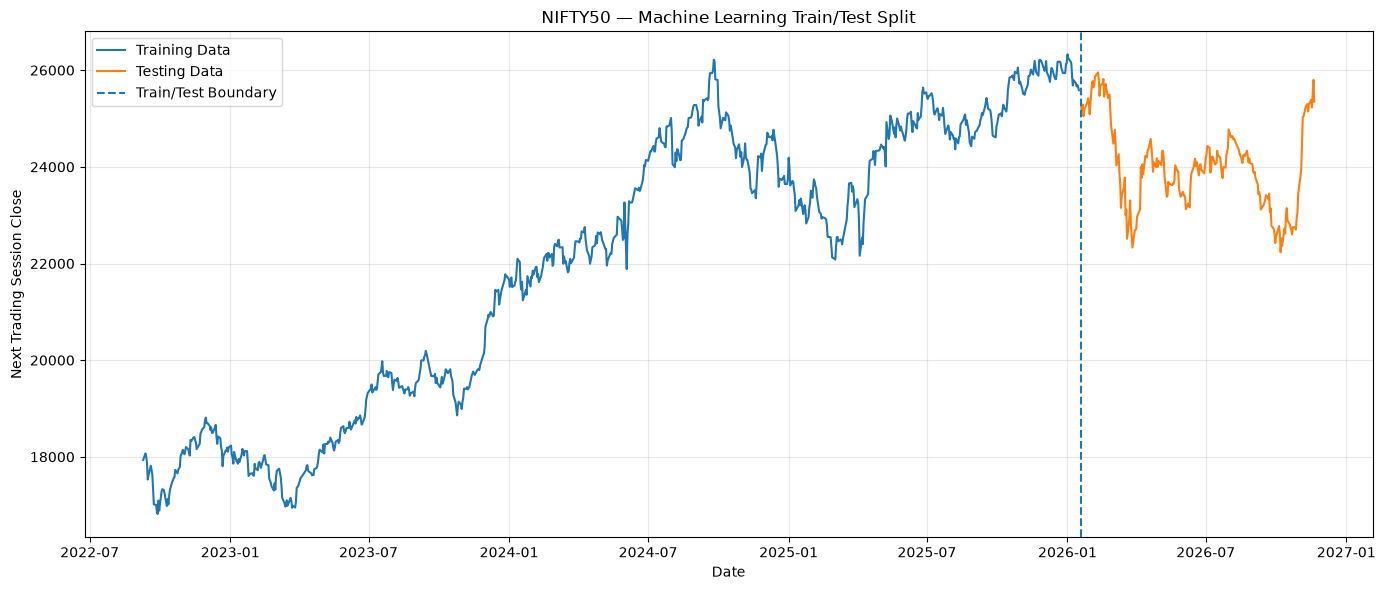

In [15]:
plt.figure(figsize=(14, 6))

plt.plot(
    nifty_split["train_df"]["date"],
    nifty_split["y_train"],
    label="Training Data"
)

plt.plot(
    nifty_split["test_df"]["date"],
    nifty_split["y_test"],
    label="Testing Data"
)

plt.axvline(
    nifty_split["test_df"]["date"].iloc[0],
    linestyle="--",
    label="Train/Test Boundary"
)

plt.title("NIFTY50 — Machine Learning Train/Test Split")
plt.xlabel("Date")
plt.ylabel("Next Trading Session Close")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [16]:
def create_models():

    models = {

        "Linear Regression": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("model", LinearRegression())
        ]),

        "Decision Tree": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", DecisionTreeRegressor(
                max_depth=8,
                min_samples_leaf=10,
                random_state=RANDOM_STATE
            ))
        ]),

        "Random Forest": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", RandomForestRegressor(
                n_estimators=200,
                max_depth=12,
                min_samples_leaf=5,
                max_features=0.8,
                random_state=RANDOM_STATE,
                n_jobs=-1
            ))
        ]),

        "Gradient Boosting": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", GradientBoostingRegressor(
                n_estimators=150,
                learning_rate=0.05,
                max_depth=3,
                loss="huber",
                random_state=RANDOM_STATE
            ))
        ])
    }

    # XGBoost is optional.
    try:
        from xgboost import XGBRegressor

        models["XGBoost"] = Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", XGBRegressor(
                n_estimators=200,
                learning_rate=0.05,
                max_depth=4,
                subsample=0.8,
                colsample_bytree=0.8,
                objective="reg:squarederror",
                random_state=RANDOM_STATE,
                n_jobs=-1
            ))
        ])

        print("XGBoost successfully loaded.")

    except Exception as error:
        print("XGBoost unavailable:", error)
        print("Continuing with four other models.")

    return models


models = create_models()

print("\nModels available:")

for model_name in models:
    print("-", model_name)

XGBoost successfully loaded.

Models available:
- Linear Regression
- Decision Tree
- Random Forest
- Gradient Boosting
- XGBoost


In [17]:
def calculate_ml_metrics(actual, predicted, current_price):

    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    current_price = np.asarray(current_price, dtype=float)

    valid = (
        np.isfinite(actual)
        & np.isfinite(predicted)
        & np.isfinite(current_price)
    )

    actual = actual[valid]
    predicted = predicted[valid]
    current_price = current_price[valid]

    if len(actual) == 0:
        return {
            "MAE": np.nan,
            "RMSE": np.nan,
            "MAPE": np.nan,
            "R2": np.nan,
            "Directional_Accuracy": np.nan
        }

    mae = mean_absolute_error(actual, predicted)

    rmse = np.sqrt(
        mean_squared_error(actual, predicted)
    )

    nonzero = actual != 0

    mape = (
        np.mean(
            np.abs(
                (actual[nonzero] - predicted[nonzero])
                / actual[nonzero]
            )
        ) * 100
        if nonzero.any()
        else np.nan
    )

    r2 = (
        r2_score(actual, predicted)
        if len(actual) >= 2
        else np.nan
    )

    actual_direction = np.sign(actual - current_price)
    predicted_direction = np.sign(predicted - current_price)

    directional_accuracy = np.mean(
        actual_direction == predicted_direction
    ) * 100

    return {
        "MAE": mae,
        "RMSE": rmse,
        "MAPE": mape,
        "R2": r2,
        "Directional_Accuracy": directional_accuracy
    }

In [18]:
nifty_model_results = []
nifty_predictions = {}
nifty_trained_models = {}

for model_name, model_template in models.items():

    print(f"\nTraining {model_name}...")

    try:
        model = clone(model_template)

        model.fit(
            nifty_split["X_train"],
            nifty_split["y_train"]
        )

        predictions = model.predict(
            nifty_split["X_test"]
        )

        nifty_trained_models[model_name] = model
        nifty_predictions[model_name] = predictions

        metrics = calculate_ml_metrics(
            nifty_split["y_test"],
            predictions,
            nifty_split["test_df"][CURRENT_PRICE_COLUMN]
        )

        nifty_model_results.append({
            "Instrument": "NIFTY50",
            "Model": model_name,
            **metrics
        })

        print("Completed:", model_name)

    except Exception as error:
        print(f"{model_name} failed: {error}")


nifty_ml_results = pd.DataFrame(nifty_model_results)

if nifty_ml_results.empty:
    raise RuntimeError(
        "All NIFTY50 machine learning models failed."
    )

display(
    nifty_ml_results.sort_values("RMSE").reset_index(drop=True)
)


Training Linear Regression...
Completed: Linear Regression

Training Decision Tree...
Completed: Decision Tree

Training Random Forest...
Completed: Random Forest

Training Gradient Boosting...
Completed: Gradient Boosting

Training XGBoost...
Completed: XGBoost


,Instrument,Model,MAE,RMSE,MAPE,R2,Directional_Accuracy
0,NIFTY50,Random Forest,185.014240,241.723859,0.771843,0.925563,51.207729
1,NIFTY50,XGBoost,179.440208,246.026672,0.748359,0.922889,53.140097
2,NIFTY50,Gradient Boosting,186.072391,254.525698,0.777523,0.917470,54.589372
3,NIFTY50,Decision Tree,206.794746,274.677686,0.863481,0.903884,47.826087
4,NIFTY50,Linear Regression,346.849866,423.720613,1.463809,0.771277,51.690821


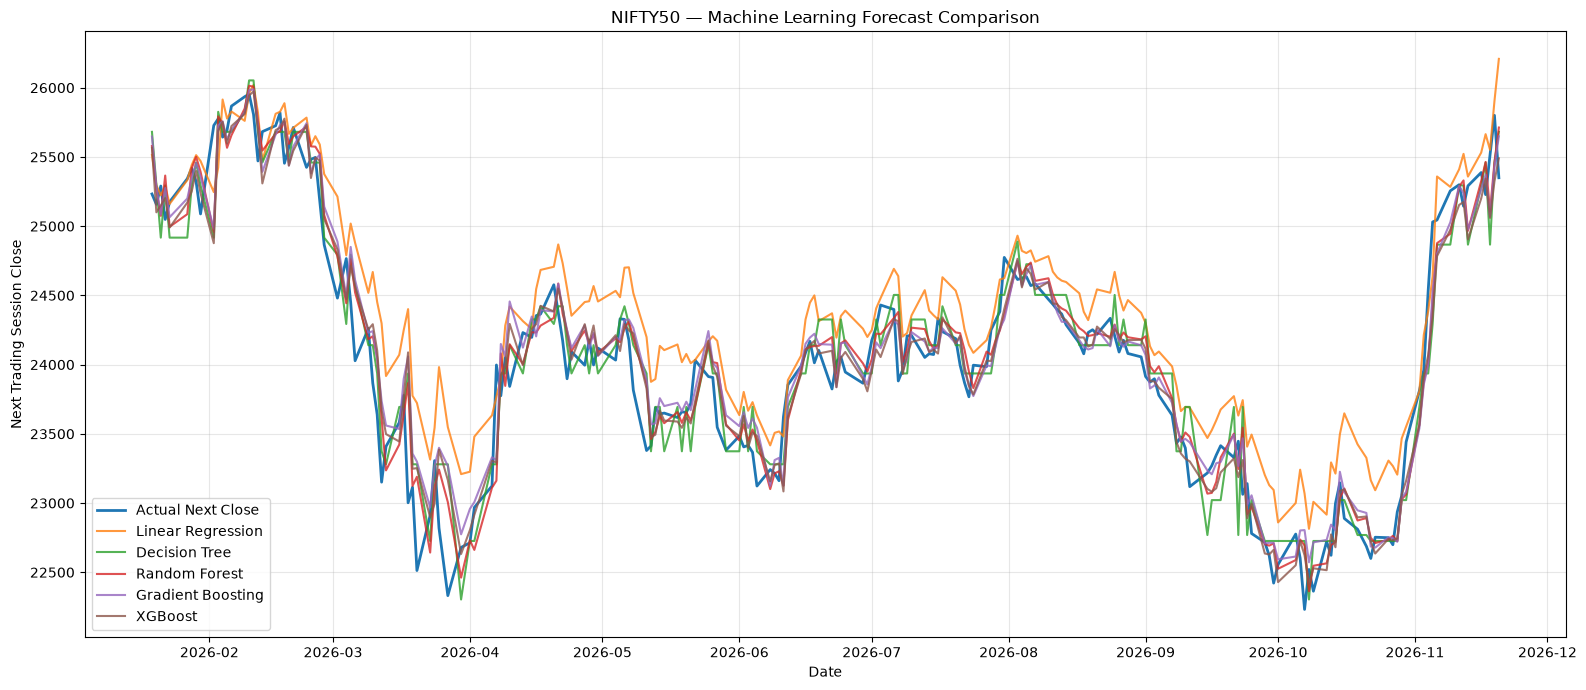

In [19]:
plt.figure(figsize=(16, 7))

test_dates = nifty_split["test_df"]["date"]

plt.plot(
    test_dates,
    nifty_split["y_test"].values,
    label="Actual Next Close",
    linewidth=2
)

for model_name, predictions in nifty_predictions.items():

    plt.plot(
        test_dates,
        predictions,
        label=model_name,
        alpha=0.8
    )

plt.title("NIFTY50 — Machine Learning Forecast Comparison")
plt.xlabel("Date")
plt.ylabel("Next Trading Session Close")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

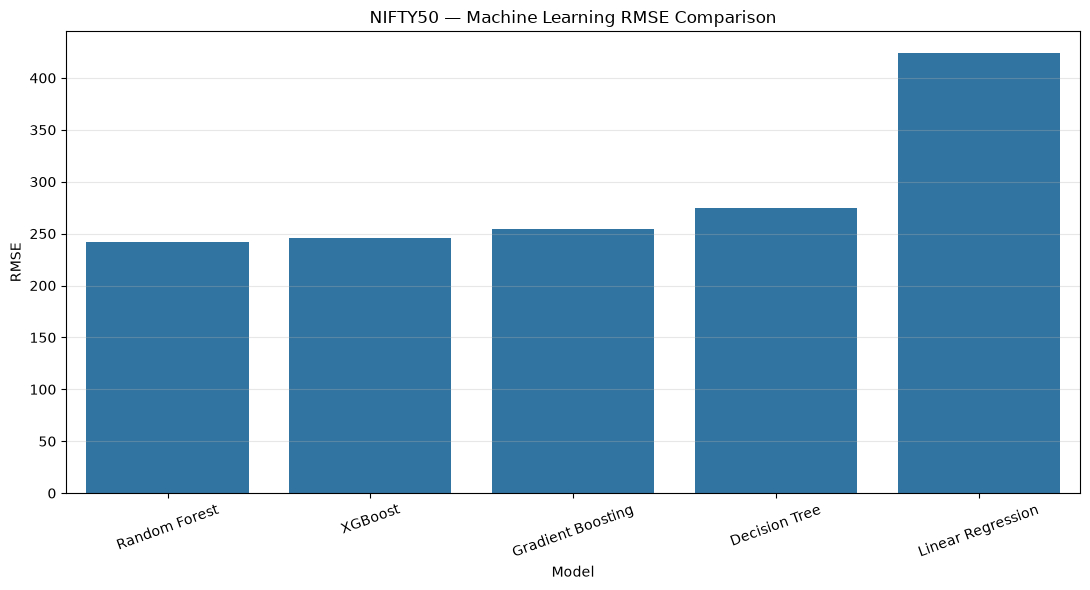

,Instrument,Model,MAE,RMSE,MAPE,R2,Directional_Accuracy
0,NIFTY50,Linear Regression,346.8499,423.7206,1.4638,0.7713,51.6908
1,NIFTY50,Decision Tree,206.7947,274.6777,0.8635,0.9039,47.8261
2,NIFTY50,Random Forest,185.0142,241.7239,0.7718,0.9256,51.2077
3,NIFTY50,Gradient Boosting,186.0724,254.5257,0.7775,0.9175,54.5894
4,NIFTY50,XGBoost,179.4402,246.0267,0.7484,0.9229,53.1401


In [20]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=nifty_ml_results.sort_values("RMSE"),
    x="Model",
    y="RMSE"
)

plt.title("NIFTY50 — Machine Learning RMSE Comparison")
plt.xlabel("Model")
plt.ylabel("RMSE")
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

display(nifty_ml_results.round(4))

In [21]:
all_ml_results = []
all_ml_predictions = []

trained_models = {}
feature_columns_by_symbol = {}
split_information = {}

for symbol, df in market_data.items():

    print("\n" + "=" * 60)
    print("Processing:", symbol)
    print("=" * 60)

    try:
        split = prepare_train_test(df)

        feature_columns_by_symbol[symbol] = split["features"]

        split_information[symbol] = {
            "train_rows": len(split["X_train"]),
            "test_rows": len(split["X_test"]),
            "features": len(split["features"]),
            "train_end": split["train_df"]["date"].max(),
            "test_start": split["test_df"]["date"].min()
        }

        for model_name, model_template in models.items():

            try:
                model = clone(model_template)

                model.fit(
                    split["X_train"],
                    split["y_train"]
                )

                predictions = model.predict(
                    split["X_test"]
                )

                metrics = calculate_ml_metrics(
                    split["y_test"],
                    predictions,
                    split["test_df"][CURRENT_PRICE_COLUMN]
                )

                all_ml_results.append({
                    "Instrument": symbol,
                    "Model": model_name,
                    "Training_Rows": len(split["X_train"]),
                    "Testing_Rows": len(split["X_test"]),
                    "Feature_Count": len(split["features"]),
                    **metrics
                })

                trained_models[(symbol, model_name)] = model

                for date, current, actual, predicted in zip(
                    split["test_df"]["date"],
                    split["test_df"][CURRENT_PRICE_COLUMN],
                    split["y_test"],
                    predictions
                ):

                    all_ml_predictions.append({
                        "Date": date,
                        "Instrument": symbol,
                        "Model": model_name,
                        "Current_Close": current,
                        "Actual_Next_Close": actual,
                        "Predicted_Next_Close": predicted,
                        "Prediction_Error": actual - predicted,
                        "Absolute_Error": abs(actual - predicted),
                        "Actual_Direction": int(
                            np.sign(actual - current)
                        ),
                        "Predicted_Direction": int(
                            np.sign(predicted - current)
                        )
                    })

                print(f"{model_name}: completed")

            except Exception as error:
                print(f"{model_name}: FAILED — {error}")

    except Exception as error:
        print(f"Skipping {symbol}: {error}")


ml_results_df = pd.DataFrame(all_ml_results)

ml_predictions_df = pd.DataFrame(
    all_ml_predictions
)

print("\nMachine learning evaluation completed.")
print("Evaluation records:", len(ml_results_df))
print("Prediction records:", len(ml_predictions_df))

display(ml_results_df.head(20))


Processing: NIFTY50
Linear Regression: completed
Decision Tree: completed
Random Forest: completed
Gradient Boosting: completed
XGBoost: completed

Processing: BANKNIFTY
Linear Regression: completed
Decision Tree: completed
Random Forest: completed
Gradient Boosting: completed
XGBoost: completed

Processing: RELIANCE
Linear Regression: completed
Decision Tree: completed
Random Forest: completed
Gradient Boosting: completed
XGBoost: completed

Processing: TCS
Linear Regression: completed
Decision Tree: completed
Random Forest: completed
Gradient Boosting: completed
XGBoost: completed

Processing: HDFCBANK
Linear Regression: completed
Decision Tree: completed
Random Forest: completed
Gradient Boosting: completed
XGBoost: completed

Processing: INFY
Linear Regression: completed
Decision Tree: completed
Random Forest: completed
Gradient Boosting: completed
XGBoost: completed

Processing: ICICIBANK
Linear Regression: completed
Decision Tree: completed
Random Forest: completed
Gradient Boos

,Instrument,Model,Training_Rows,Testing_Rows,Feature_Count,MAE,RMSE,MAPE,R2,Directional_Accuracy
0,NIFTY50,Linear Regression,827,207,62,346.849866,423.720613,1.463809,0.771277,51.690821
1,NIFTY50,Decision Tree,827,207,62,206.794746,274.677686,0.863481,0.903884,47.826087
2,NIFTY50,Random Forest,827,207,62,185.014240,241.723859,0.771843,0.925563,51.207729
3,NIFTY50,Gradient Boosting,827,207,62,186.072391,254.525698,0.777523,0.917470,54.589372
4,NIFTY50,XGBoost,827,207,62,179.440208,246.026672,0.748359,0.922889,53.140097
5,BANKNIFTY,Linear Regression,826,207,62,671.723953,837.067898,1.191241,0.884961,46.859903
6,BANKNIFTY,Decision Tree,826,207,62,1384.302717,1852.821459,2.444341,0.436376,50.241546
7,BANKNIFTY,Random Forest,826,207,62,1050.537767,1350.391651,1.853944,0.700607,50.241546
8,BANKNIFTY,Gradient Boosting,826,207,62,845.866825,1177.159206,1.476433,0.772494,51.207729
9,BANKNIFTY,XGBoost,826,207,62,740.411477,1084.472332,1.285281,0.806910,50.724638


In [22]:
baseline_results = []
baseline_predictions = []

for symbol, df in market_data.items():

    try:
        split = prepare_train_test(df)

        predictions = split["test_df"][
            CURRENT_PRICE_COLUMN
        ].values

        metrics = calculate_ml_metrics(
            split["y_test"],
            predictions,
            split["test_df"][CURRENT_PRICE_COLUMN]
        )

        baseline_results.append({
            "Instrument": symbol,
            "Model": "Persistence Baseline",
            "Training_Rows": len(split["X_train"]),
            "Testing_Rows": len(split["X_test"]),
            "Feature_Count": 0,
            **metrics
        })

        for date, current, actual, predicted in zip(
            split["test_df"]["date"],
            split["test_df"][CURRENT_PRICE_COLUMN],
            split["y_test"],
            predictions
        ):

            baseline_predictions.append({
                "Date": date,
                "Instrument": symbol,
                "Model": "Persistence Baseline",
                "Current_Close": current,
                "Actual_Next_Close": actual,
                "Predicted_Next_Close": predicted,
                "Prediction_Error": actual - predicted,
                "Absolute_Error": abs(actual - predicted),
                "Actual_Direction": int(np.sign(actual - current)),
                "Predicted_Direction": int(np.sign(predicted - current))
            })

    except Exception as error:
        print(symbol, "baseline failed:", error)


baseline_df = pd.DataFrame(baseline_results)

baseline_predictions_df = pd.DataFrame(
    baseline_predictions
)

comparison_results = pd.concat(
    [ml_results_df, baseline_df],
    ignore_index=True
)

print("Machine learning versus persistence baseline:")

display(
    comparison_results.sort_values(
        ["Instrument", "RMSE"]
    ).reset_index(drop=True)
)

Machine learning versus persistence baseline:


,Instrument,Model,Training_Rows,Testing_Rows,Feature_Count,MAE,RMSE,MAPE,R2,Directional_Accuracy
0,BANKNIFTY,Persistence Baseline,826,207,0,512.323068,697.653949,0.905977,0.920090,0.000000
1,BANKNIFTY,Linear Regression,826,207,62,671.723953,837.067898,1.191241,0.884961,46.859903
2,BANKNIFTY,XGBoost,826,207,62,740.411477,1084.472332,1.285281,0.806910,50.724638
3,BANKNIFTY,Gradient Boosting,826,207,62,845.866825,1177.159206,1.476433,0.772494,51.207729
4,BANKNIFTY,Random Forest,826,207,62,1050.537767,1350.391651,1.853944,0.700607,50.241546
5,BANKNIFTY,Decision Tree,826,207,62,1384.302717,1852.821459,2.444341,0.436376,50.241546
6,HDFCBANK,Persistence Baseline,829,208,0,9.517786,12.551647,1.218280,0.967919,0.961538
7,HDFCBANK,Linear Regression,829,208,62,11.104287,14.100823,1.420315,0.959511,42.307692
8,HDFCBANK,Random Forest,829,208,62,11.653213,14.643815,1.507999,0.956333,43.750000
9,HDFCBANK,Gradient Boosting,829,208,62,12.573317,15.847964,1.619541,0.948857,44.711538


In [23]:
best_ml_models = (
    comparison_results
    .dropna(subset=["RMSE"])
    .sort_values(["Instrument", "RMSE"])
    .groupby("Instrument")
    .first()
    .reset_index()
)

display(best_ml_models)

,Instrument,Model,Training_Rows,Testing_Rows,Feature_Count,MAE,RMSE,MAPE,R2,Directional_Accuracy
0,BANKNIFTY,Persistence Baseline,826,207,0,512.323068,697.653949,0.905977,0.920090,0.000000
1,HDFCBANK,Persistence Baseline,829,208,0,9.517786,12.551647,1.218280,0.967919,0.961538
2,ICICIBANK,Persistence Baseline,829,208,0,14.522595,19.130837,1.065474,0.948775,0.000000
3,INFY,Persistence Baseline,829,208,0,18.599996,25.238324,1.574464,0.973494,0.000000
4,ITC,Persistence Baseline,829,208,0,3.008174,4.034160,1.041165,0.959252,0.480769
5,LT,Persistence Baseline,829,208,0,47.333156,66.619954,1.213964,0.884953,0.000000
6,NIFTY50,Persistence Baseline,827,207,0,177.903146,232.165886,0.743396,0.931333,0.000000
7,RELIANCE,Persistence Baseline,829,208,0,14.810093,20.622213,1.119166,0.919639,0.480769
8,SBIN,Persistence Baseline,829,208,0,12.750238,17.378957,1.219660,0.932421,0.480769
9,TCS,Persistence Baseline,829,208,0,35.138945,49.346365,1.463200,0.965005,0.000000


In [24]:
feature_importance_rows = []

TREE_MODELS = [
    "Decision Tree",
    "Random Forest",
    "Gradient Boosting",
    "XGBoost"
]

for (symbol, model_name), pipeline in trained_models.items():

    if model_name not in TREE_MODELS:
        continue

    try:
        estimator = pipeline.named_steps["model"]

        if not hasattr(estimator, "feature_importances_"):
            continue

        features = feature_columns_by_symbol[symbol]

        for feature, importance in zip(
            features,
            estimator.feature_importances_
        ):

            feature_importance_rows.append({
                "Instrument": symbol,
                "Model": model_name,
                "Feature": feature,
                "Importance": importance
            })

    except Exception as error:
        print(
            f"Feature importance failed: "
            f"{symbol}, {model_name}: {error}"
        )


feature_importance_df = pd.DataFrame(
    feature_importance_rows
)

display(
    feature_importance_df.head(20)
)

,Instrument,Model,Feature,Importance
0,NIFTY50,Decision Tree,adj_close,0.016423
1,NIFTY50,Decision Tree,close,0.117609
2,NIFTY50,Decision Tree,high,0.003521
3,NIFTY50,Decision Tree,low,0.000062
4,NIFTY50,Decision Tree,open,0.000019
5,NIFTY50,Decision Tree,volume,0.000017
6,NIFTY50,Decision Tree,daily_return,0.000012
7,NIFTY50,Decision Tree,weekly_return,0.000000
8,NIFTY50,Decision Tree,monthly_return,0.000048
9,NIFTY50,Decision Tree,sma_5,0.000000


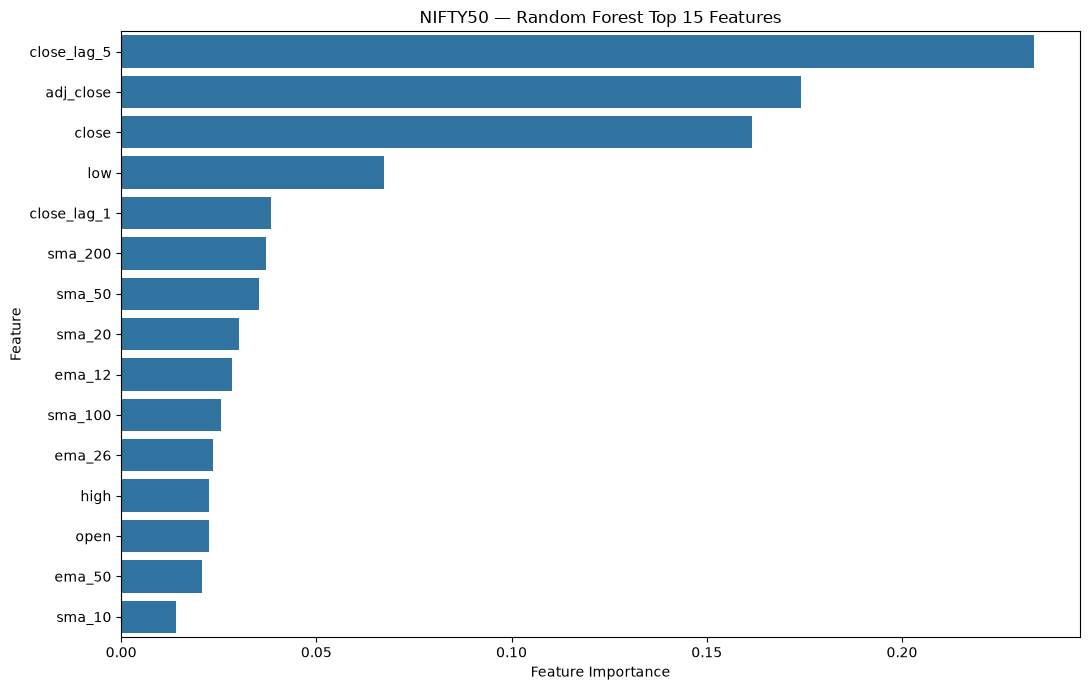

In [25]:
nifty_rf_importance = feature_importance_df[
    (feature_importance_df["Instrument"] == "NIFTY50")
    & (feature_importance_df["Model"] == "Random Forest")
].sort_values(
    "Importance",
    ascending=False
).head(15)

if not nifty_rf_importance.empty:

    plt.figure(figsize=(11, 7))

    sns.barplot(
        data=nifty_rf_importance,
        x="Importance",
        y="Feature"
    )

    plt.title("NIFTY50 — Random Forest Top 15 Features")
    plt.xlabel("Feature Importance")
    plt.ylabel("Feature")
    plt.tight_layout()
    plt.show()

else:
    print("NIFTY50 Random Forest importance unavailable.")

In [26]:
if not ml_predictions_df.empty:

    ml_predictions_df["Absolute_Percentage_Error"] = (
        ml_predictions_df["Absolute_Error"]
        / ml_predictions_df["Actual_Next_Close"].abs()
    ) * 100

    display(
        ml_predictions_df.sort_values(
            "Absolute_Error",
            ascending=False
        ).head(20)
    )

else:
    print("No machine learning predictions available.")

,Date,Instrument,Model,Current_Close,Actual_Next_Close,Predicted_Next_Close,Prediction_Error,Absolute_Error,Actual_Direction,Predicted_Direction,Absolute_Percentage_Error
1447,2026-11-19,BANKNIFTY,Decision Tree,63063.000000,64635.199219,57855.095313,6780.103906,6780.103906,1,-1,10.489801
1861,2026-11-19,BANKNIFTY,Gradient Boosting,63063.000000,64635.199219,59106.213318,5528.985901,5528.985901,1,-1,8.554141
2068,2026-11-19,BANKNIFTY,XGBoost,63063.000000,64635.199219,59204.671875,5430.527344,5430.527344,1,-1,8.401811
1654,2026-11-19,BANKNIFTY,Random Forest,63063.000000,64635.199219,59324.695497,5310.503722,5310.503722,1,-1,8.216117
1446,2026-11-18,BANKNIFTY,Decision Tree,62038.648438,63063.000000,57855.095313,5207.904687,5207.904687,1,-1,8.258257
1448,2026-11-20,BANKNIFTY,Decision Tree,64635.199219,62585.351562,57855.095313,4730.256250,4730.256250,-1,-1,7.558088
1444,2026-11-16,BANKNIFTY,Decision Tree,61575.898438,62273.250000,57855.095313,4418.154687,4418.154687,1,-1,7.094787
1282,2026-03-18,BANKNIFTY,Decision Tree,55326.050781,53451.000000,57855.095313,-4404.095313,4404.095313,-1,1,8.239500
2067,2026-11-18,BANKNIFTY,XGBoost,62038.648438,63063.000000,58811.406250,4251.593750,4251.593750,1,-1,6.741820
1445,2026-11-17,BANKNIFTY,Decision Tree,62273.250000,62038.648438,57855.095313,4183.553125,4183.553125,-1,-1,6.743463


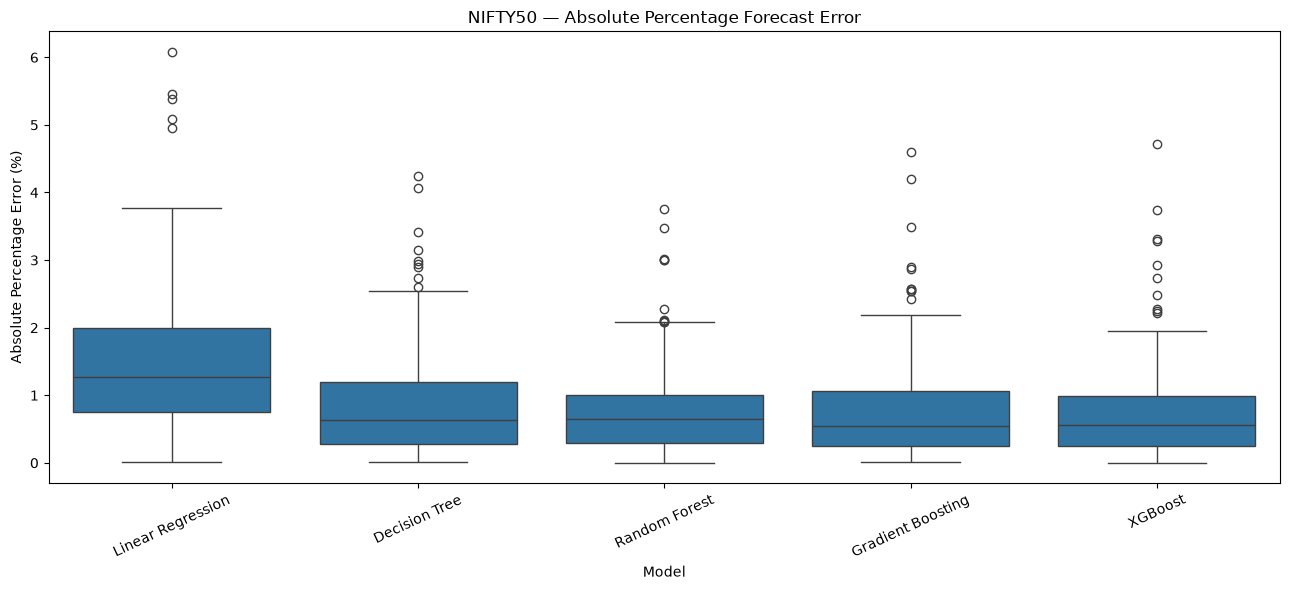

In [27]:
nifty_error_data = ml_predictions_df[
    ml_predictions_df["Instrument"] == "NIFTY50"
].copy()

if not nifty_error_data.empty:

    plt.figure(figsize=(13, 6))

    sns.boxplot(
        data=nifty_error_data,
        x="Model",
        y="Absolute_Percentage_Error"
    )

    plt.title("NIFTY50 — Absolute Percentage Forecast Error")
    plt.xlabel("Model")
    plt.ylabel("Absolute Percentage Error (%)")
    plt.xticks(rotation=25)
    plt.tight_layout()
    plt.show()

In [28]:
saved_model_records = []

for (symbol, model_name), model in trained_models.items():

    safe_model_name = (
        model_name.lower()
        .replace(" ", "_")
        .replace("(", "")
        .replace(")", "")
        .replace(",", "")
    )

    model_filename = (
        f"{symbol}_{safe_model_name}.joblib"
    )

    model_path = os.path.join(
        MODEL_DIR,
        model_filename
    )

    joblib.dump(model, model_path)

    saved_model_records.append({
        "Instrument": symbol,
        "Model": model_name,
        "Filename": model_filename,
        "Path": model_path
    })


saved_models_df = pd.DataFrame(
    saved_model_records
)

display(saved_models_df.head(20))

print("Total saved models:", len(saved_models_df))

,Instrument,Model,Filename,Path
0,NIFTY50,Linear Regression,NIFTY50_linear_regression.joblib,C:\Users\adity\Downloads\Historical data\Bhara...
1,NIFTY50,Decision Tree,NIFTY50_decision_tree.joblib,C:\Users\adity\Downloads\Historical data\Bhara...
2,NIFTY50,Random Forest,NIFTY50_random_forest.joblib,C:\Users\adity\Downloads\Historical data\Bhara...
3,NIFTY50,Gradient Boosting,NIFTY50_gradient_boosting.joblib,C:\Users\adity\Downloads\Historical data\Bhara...
4,NIFTY50,XGBoost,NIFTY50_xgboost.joblib,C:\Users\adity\Downloads\Historical data\Bhara...
5,BANKNIFTY,Linear Regression,BANKNIFTY_linear_regression.joblib,C:\Users\adity\Downloads\Historical data\Bhara...
6,BANKNIFTY,Decision Tree,BANKNIFTY_decision_tree.joblib,C:\Users\adity\Downloads\Historical data\Bhara...
7,BANKNIFTY,Random Forest,BANKNIFTY_random_forest.joblib,C:\Users\adity\Downloads\Historical data\Bhara...
8,BANKNIFTY,Gradient Boosting,BANKNIFTY_gradient_boosting.joblib,C:\Users\adity\Downloads\Historical data\Bhara...
9,BANKNIFTY,XGBoost,BANKNIFTY_xgboost.joblib,C:\Users\adity\Downloads\Historical data\Bhara...


Total saved models: 50


In [29]:
feature_metadata = []

for symbol, features in feature_columns_by_symbol.items():

    for position, feature in enumerate(features, start=1):

        feature_metadata.append({
            "Instrument": symbol,
            "Feature_Position": position,
            "Feature_Name": feature
        })


feature_metadata_df = pd.DataFrame(
    feature_metadata
)

display(feature_metadata_df.head(20))

,Instrument,Feature_Position,Feature_Name
0,NIFTY50,1,adj_close
1,NIFTY50,2,close
2,NIFTY50,3,high
3,NIFTY50,4,low
4,NIFTY50,5,open
5,NIFTY50,6,volume
6,NIFTY50,7,daily_return
7,NIFTY50,8,weekly_return
8,NIFTY50,9,monthly_return
9,NIFTY50,10,sma_5


In [30]:
comparison_results.to_csv(
    os.path.join(
        REPORT_DIR,
        "machine_learning_model_comparison.csv"
    ),
    index=False
)

best_ml_models.to_csv(
    os.path.join(
        REPORT_DIR,
        "best_machine_learning_models.csv"
    ),
    index=False
)

feature_importance_df.to_csv(
    os.path.join(
        REPORT_DIR,
        "machine_learning_feature_importance.csv"
    ),
    index=False
)

saved_models_df.to_csv(
    os.path.join(
        REPORT_DIR,
        "saved_machine_learning_models.csv"
    ),
    index=False
)

feature_metadata_df.to_csv(
    os.path.join(
        REPORT_DIR,
        "machine_learning_feature_metadata.csv"
    ),
    index=False
)

all_predictions_df = pd.concat(
    [ml_predictions_df, baseline_predictions_df],
    ignore_index=True
)

all_predictions_df.to_csv(
    os.path.join(
        FORECAST_DIR,
        "machine_learning_predictions.csv"
    ),
    index=False
)

print("All reports and predictions exported successfully.")

All reports and predictions exported successfully.


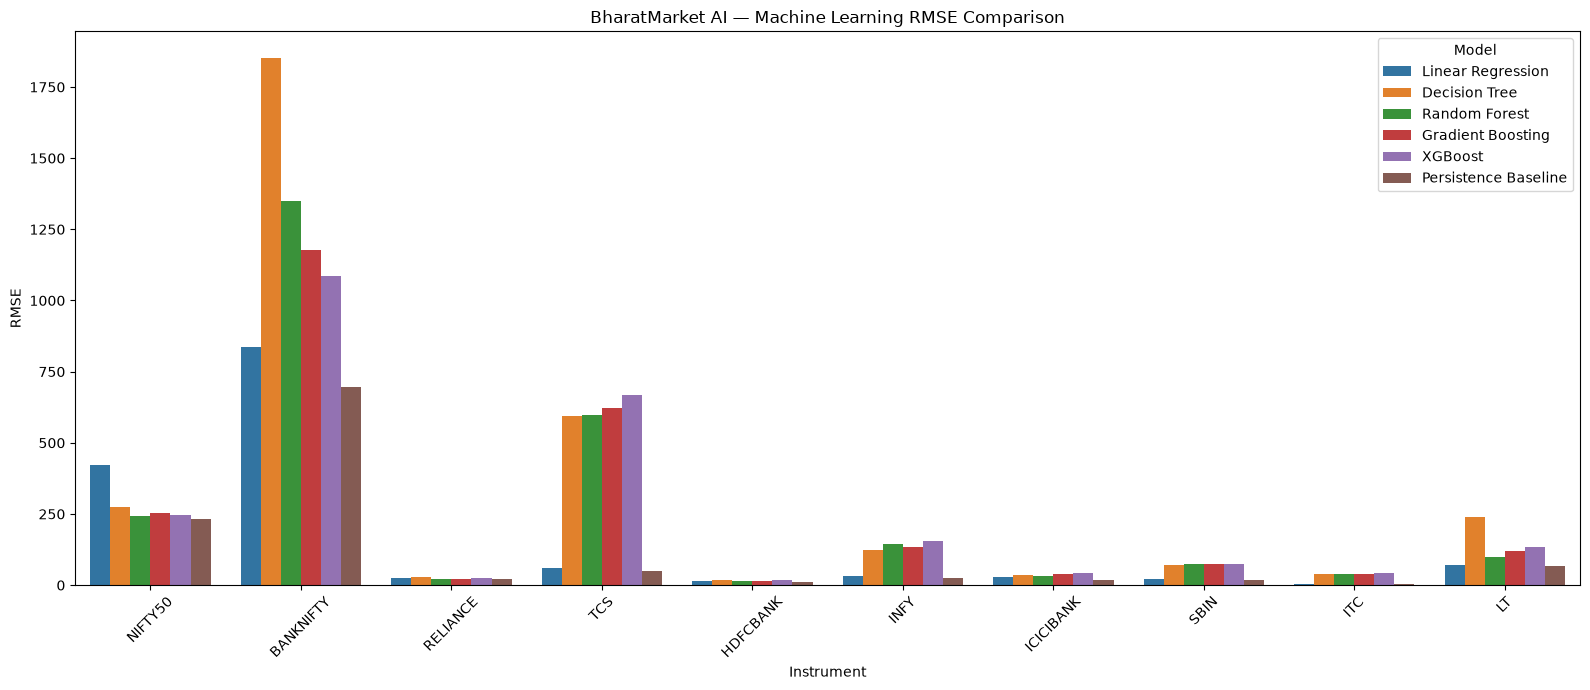

Chart saved: C:\Users\adity\Downloads\Historical data\BharatMarket_AI\outputs\charts\machine_learning_rmse_comparison.png


In [31]:
if not comparison_results.empty:

    plt.figure(figsize=(16, 7))

    sns.barplot(
        data=comparison_results,
        x="Instrument",
        y="RMSE",
        hue="Model"
    )

    plt.title(
        "BharatMarket AI — Machine Learning RMSE Comparison"
    )

    plt.xlabel("Instrument")
    plt.ylabel("RMSE")
    plt.xticks(rotation=45)
    plt.legend(title="Model")
    plt.tight_layout()

    chart_path = os.path.join(
        CHART_DIR,
        "machine_learning_rmse_comparison.png"
    )

    plt.savefig(
        chart_path,
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()

    print("Chart saved:", chart_path)

else:
    print("No evaluation results available.")

In [32]:
summary = {
    "Project": "BharatMarket AI",
    "Notebook": "07 - Machine Learning Forecasting",
    "Instruments Loaded": len(market_data),
    "Instruments Evaluated": (
        comparison_results["Instrument"].nunique()
        if not comparison_results.empty else 0
    ),
    "Machine Learning Models": len(models),
    "Target Column": TARGET_COLUMN,
    "Prediction Target": "Next Trading Session Closing Price",
    "Train Test Split": "80% Training / 20% Testing",
    "Validation Type": "Chronological Holdout",
    "Evaluation Metrics": (
        "MAE, RMSE, MAPE, R2, Directional Accuracy"
    ),
    "Baseline": "Persistence Model",
    "Feature Importance": "Tree-Based Feature Importance",
    "Model Format": "Joblib",
    "Models Saved": len(saved_models_df),
    "Forecast Output": "machine_learning_predictions.csv"
}

summary_df = pd.DataFrame(
    list(summary.items()),
    columns=["Item", "Value"]
)

display(summary_df)

summary_df.to_csv(
    os.path.join(
        REPORT_DIR,
        "notebook_07_summary.csv"
    ),
    index=False
)

print("\n" + "=" * 55)
print("NOTEBOOK 07 COMPLETED")
print("=" * 55)

,Item,Value
0,Project,BharatMarket AI
1,Notebook,07 - Machine Learning Forecasting
2,Instruments Loaded,10
3,Instruments Evaluated,10
4,Machine Learning Models,5
5,Target Column,target_next_close
6,Prediction Target,Next Trading Session Closing Price
7,Train Test Split,80% Training / 20% Testing
8,Validation Type,Chronological Holdout
9,Evaluation Metrics,"MAE, RMSE, MAPE, R2, Directional Accuracy"



NOTEBOOK 07 COMPLETED
